# 12. Check seeds and formatting robustness

Owner: Jalil-g. Issue #12. Depends on completed #11.

## Goal

Measure how much the #11 primary soft ensemble moves with the inner split, the solver seed, and simple formatting changes. Everything stays inside original8000; frozen2000 is not scored here.

## Setup

Reuse #11 factories with `FORMATTING_RULE_HELPERS_ONLY=1`, so nothing from #11 fits or writes. Arms are the #11 soft members: `rule_all_wordchar16` and `rule_no_blank_case_svm1`, soft offset 2. Solver seed goes into the classifier `random_state`; everything else is the exact #10/#11 setting.

In [1]:
import os, json, time, textwrap, warnings, gc, traceback
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import roc_auc_score
from threadpoolctl import threadpool_limits
os.environ["FORMATTING_RULE_HELPERS_ONLY"] = "1"
get_ipython().run_line_magic("run", "./11_formatting_rule.ipynb")

NAME = "12_seed_stress"
COMMAND = "uv run --locked jupyter nbconvert --execute --to notebook --inplace --ExecutePreprocessor.timeout=3600 notebooks/12_seed_stress.ipynb"
SPLIT_SEEDS = [42, 7, 2026]   # inner 6400/1600 splits, solver fixed at 42
SOLVER_SEEDS = [42, 7, 2026]  # solver seeds on fixed inner split 42
INNER_EVAL_PER_CLASS = 800
MODES = {"off": 0., "soft": 2., "hard": 1000.}  # rule off, #11 primary, #11 hard ablation
CONDITIONS = ([{"name": f"split{s}_solver42", "split_seed": s, "solver_seed": 42} for s in SPLIT_SEEDS] +
              [{"name": f"split42_solver{s}", "split_seed": 42, "solver_seed": s} for s in SOLVER_SEEDS if s != 42])

# Wrap the #10 factory so FormattingArm picks up the solver seed from its candidate dict.
base_expanded_model = make_expanded_model
def make_expanded_model(candidate):
    return base_expanded_model(candidate).set_params(classifier__random_state=int(candidate.get("solver_seed", 42)))

## Checks

Notebook 02 checks data bytes, duplicate audit, and the frozen split. #11 must have a completed record whose notebook source still matches. Inner splits keep duplicate groups whole and use exact 800/800 class quotas. Stress functions are tested on synthetic strings only.

In [2]:
START = time.perf_counter()
parts = load_partitions()
train, reference = parts["train"], parts["unlabeled"]  # frozen validation is not used here
records = [(p, json.loads(p.read_text())) for p in sorted((ROOT/"results/11_formatting_rule").glob("2*Z.json"))]
records = [(p, r) for p, r in records if r.get("status") == "completed"]
require(bool(records), "Completed #11 is required")
dependency_path, dependency = records[-1]
nb11_hash = value_hash(["".join(c["source"]) for c in json.loads((ROOT/"notebooks/11_formatting_rule.ipynb").read_text())["cells"]])
require(nb11_hash == dependency["config"]["notebook_source_sha256"], "Notebook 11 source changed since its recorded run")
members = dependency["metrics"]["selections"]["soft"]["selected"]
ARMS = [c for c in FORMATTING_GRID if c["name"] in members]
require([c["name"] for c in ARMS] == members == ["rule_all_wordchar16", "rule_no_blank_case_svm1"], "Unexpected #11 soft members")

_, components, _ = checked_audit(ROOT / parts["split"]["audit_path"])
train_ids = set(train.id)
inner_components = [[row for row in comp if row["file"] == "train.csv" and row["id"] in train_ids] for comp in components]
inner_components = [comp for comp in inner_components if len(comp) > 1]
indexed = train.set_index("id", drop=False)
inner_splits, split_digests = {}, {}
for seed in SPLIT_SEEDS:
    fit_ids, eval_ids = split_ids(train[["id", "label"]], inner_components, validation_per_class=INNER_EVAL_PER_CLASS, seed=seed)
    require(len(fit_ids) == 6400 and len(eval_ids) == 1600 and set(fit_ids) | set(eval_ids) == train_ids, "Bad inner split")
    require(indexed.loc[eval_ids].label.value_counts().to_dict() == {0: 800, 1: 800}, "Bad inner class quota")
    inner_splits[seed] = (indexed.loc[fit_ids].reset_index(drop=True), indexed.loc[eval_ids].reset_index(drop=True))
    split_digests[seed] = {"fit_ids_sha256": value_hash(fit_ids), "eval_ids_sha256": value_hash(eval_ids)}
overlap = {f"{a}_vs_{b}": len(set(inner_splits[a][1].id) & set(inner_splits[b][1].id)) for a, b in [(42, 7), (42, 2026), (7, 2026)]}

def remove_blank_lines(text):
    return "\n".join(line for line in str(text).split("\n") if line.strip())
def collapse_whitespace(text):
    return " ".join(str(text).split())
def wrap80(text):
    # Wrap each existing line at 80 columns; keep blank lines so only line length changes.
    return "\n".join(textwrap.fill(line, 80) if line.strip() else line for line in str(text).split("\n"))
STRESSES = {"original": str, "remove_blank_lines": remove_blank_lines, "collapse_whitespace": collapse_whitespace, "wrap80": wrap80}

sample = "a  b\n\n\nc\t d\n" + "word " * 30
require(remove_blank_lines("a\n\n\nb\n  \nc") == "a\nb\nc", "Blank-line removal failed")
require("\n\n" not in remove_blank_lines(sample) and "\n\n" not in collapse_whitespace(sample), "Stress kept a blank line")
require(collapse_whitespace(sample).startswith("a b c d word"), "Whitespace collapse failed")
require(all(len(line) <= 80 for line in wrap80(sample).split("\n")) and "\n\n" in wrap80(sample), "wrap80 failed")
require(make_expanded_model({**ARMS[1], "solver_seed": 7}).get_params()["classifier__random_state"] == 7, "Solver seed not applied")
CONFIG = {"arms": ARMS, "modes": MODES, "split_seeds": SPLIT_SEEDS, "solver_seeds": SOLVER_SEEDS, "conditions": CONDITIONS,
    "inner_split": "inside original8000 only; exact 800/800 eval quota; duplicate groups whole; notebook 02 split_ids",
    "inner_split_digests": split_digests, "eval_overlap_rows": overlap, "inner_components": len(inner_components),
    "stresses": {"original": "unchanged", "remove_blank_lines": "drop whitespace-only lines",
                 "collapse_whitespace": "all whitespace runs to one space", "wrap80": "textwrap.fill each nonblank line at 80"},
    "stress_scope": "eval rows only; fit rows and reference rows stay original; reference stats frozen from fit",
    "reference": {"rows": len(reference), "ordered_id_sha256": value_hash(reference.id.tolist())},
    "frozen_validation_used": False, "threads": 1,
    "dependency": {"record": str(dependency_path.relative_to(ROOT)), "record_sha256": file_hash(dependency_path), "source_sha256": nb11_hash},
    "notebook_source_sha256": value_hash(["".join(c["source"]) for c in json.loads((ROOT/"notebooks/12_seed_stress.ipynb").read_text())["cells"]])}
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
private = ROOT/"artifacts"/NAME/RUN_ID
private.mkdir(parents=True, exist_ok=False)
display(pd.DataFrame([{"split_seed": s, **d} for s, d in split_digests.items()]))
print("Inner eval overlap rows:", overlap, "| duplicate groups inside original8000:", len(inner_components))

,split_seed,fit_ids_sha256,eval_ids_sha256
0,42,29a43f7c5aa0e4c3b4bebc7ef727d187f2882b4cb07daf...,0f925429c4517abf05614b483502acad66cfb941d6aa70...
1,7,2d8a59b022523723023681328c0db4d20ec6ff8c40af60...,df456bc62e6f27f15d30f044a66b5ae968c4f4beea6f0a...
2,2026,9800ac0d27a21b3b72f7733ad29bb07d9cb6d7a697cc32...,5fc7a8485286bc3c7a2151a26943ed1386cafc1b65a0b1...


Inner eval overlap rows: {'42_vs_7': 306, '42_vs_2026': 316, '7_vs_2026': 324} | duplicate groups inside original8000: 0


## Method

For each of five conditions, fit both arms fresh on the 6400 fit rows. Rule eligibility, NB-free features, and margin reference stats come from fit rows and eligible unlabeled rows only, exactly as in #11. Then score the 1600 eval rows four ways: original, blank lines removed, whitespace collapsed, and wrapped at 80. Stress only touches eval text, never training text.

Score each with rule off (offset 0), soft (offset 2), and hard (offset 1000) on the same fitted ensemble. Stress loss is original AUROC minus stressed AUROC in the same condition and mode. Raw margin change is the native decision value change of each arm, so reference scaling cannot hide it.

In [3]:
def condition_scores(arms, frame):
    rows, margins, raw = [], [], {}
    for stress, change in STRESSES.items():
        texts = frame.text.map(change)
        raw[stress] = {}
        for arm in arms:
            values, _, flags = arm.components(texts)
            raw[stress][arm.candidate["name"]] = values
            margins.append({"stress": stress, "arm": arm.candidate["name"], "active_flags": int(flags.sum()),
                "max_abs_raw_change": float(np.max(np.abs(values - raw["original"][arm.candidate["name"]]))),
                "mean_abs_raw_change": float(np.mean(np.abs(values - raw["original"][arm.candidate["name"]])))})
        for mode, offset in MODES.items():
            p = class1_probabilities(FormattingEnsemble(arms, offset=offset), texts)
            rows.append({"stress": stress, "mode": mode, "auroc": float(roc_auc_score(frame.label, p)),
                         "changed_rows": int((texts != frame.text).sum()), "literal_blank_rows": int(formatting_flags(texts).sum())})
    return rows, margins, raw

## Run

Five conditions times two fresh arm fits. Raw margins go to ignored artifacts only. A failure writes a safe failed record and keeps the traceback private.

In [4]:
plan_path = ROOT/"results"/NAME/f"{RUN_ID}-plan.json"
save_new_json(plan_path, {"config": CONFIG, "config_sha256": value_hash(CONFIG), "saved_before_fit": True, "split_sha256": parts["split"]["split_sha256"]})
artifacts, auroc_rows, margin_rows, fit_rows, raw_by_condition = [plan_path], [], [], [], {}
try:
    run_start = time.perf_counter()
    with threadpool_limits(limits=1), warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        for condition in CONDITIONS:
            fit, held = inner_splits[condition["split_seed"]]
            start = time.perf_counter()
            arms = [FormattingArm({**candidate, "solver_seed": condition["solver_seed"]}).fit(fit, reference) for candidate in ARMS]
            fit_seconds = time.perf_counter() - start
            start = time.perf_counter()
            rows, margins, raw = condition_scores(arms, held)
            score_seconds = time.perf_counter() - start
            auroc_rows += [{"condition": condition["name"], **row} for row in rows]
            margin_rows += [{"condition": condition["name"], **row} for row in margins]
            raw_by_condition[condition["name"]] = raw
            fit_rows.append({"condition": condition["name"], "fit_seconds": fit_seconds, "score_seconds": score_seconds,
                **{f"{arm.candidate['name']}_rule_active": arm.audit_["rule_active"] for arm in arms},
                **{f"{arm.candidate['name']}_used_fit_rows": arm.audit_["used_fit_rows"] for arm in arms},
                **{f"{arm.candidate['name']}_reference": arm.statistics_ for arm in arms}})
            path = private/f"{condition['name']}_raw_margins.csv"
            pd.DataFrame({"id": held.id, **{f"{s}__{a}": v for s, d in raw.items() for a, v in d.items()}}).to_csv(path, index=False)
            artifacts.append(path)
            del arms; gc.collect()
    run_seconds = time.perf_counter() - run_start
except Exception as exc:
    (private/"failure_traceback.txt").write_text(traceback.format_exc())
    record_run(NAME, COMMAND, CONFIG, SEED, 6400, 1600, {"validation_auroc": None, "completed_rows": auroc_rows},
               time.perf_counter() - START, status="failed", error_type=type(exc).__name__)
    raise RuntimeError("Seed stress run failed. See safe record and ignored failure_traceback.txt.") from None

## Results

All AUROCs are on 1600 inner eval rows from original8000, not frozen2000 and not Kaggle. Solver rows share split 42, so they isolate solver randomness. Split rows share solver 42, so they isolate split sensitivity. Stress loss isolates formatting on a fixed fit.

mode                                        hard       off      soft
condition          stress                                           
split2026_solver42 collapse_whitespace  0.911931  0.911931  0.911931
                   original             0.993523  0.963822  0.993523
                   remove_blank_lines   0.960362  0.960362  0.960362
                   wrap80               0.986750  0.937866  0.986748
split42_solver2026 collapse_whitespace  0.908414  0.908414  0.908414
                   original             0.994148  0.961927  0.994148
                   remove_blank_lines   0.957148  0.957148  0.957148
                   wrap80               0.988362  0.936477  0.988348
split42_solver42   collapse_whitespace  0.908414  0.908414  0.908414
                   original             0.994148  0.961927  0.994148
                   remove_blank_lines   0.957148  0.957148  0.957148
                   wrap80               0.988362  0.936477  0.988348
split42_solver7    collapse_whitespace  0.908414  0.908414  0.908414
                   original             0.994148  0.961927  0.994148
                   remove_blank_lines   0.957148  0.957148  0.957148
                   wrap80               0.988362  0.936477  0.988348
split7_solver42    collapse_whitespace  0.891412  0.891412  0.891412
                   original             0.994048  0.960228  0.994044
                   remove_blank_lines   0.955431  0.955431  0.955431
                   wrap80               0.987711  0.927955  0.987711

,condition,fit_seconds,score_seconds,rule_all_wordchar16_rule_active,rule_no_blank_case_svm1_rule_active,rule_all_wordchar16_used_fit_rows,rule_no_blank_case_svm1_used_fit_rows
0,split42_solver42,23.559530,61.272997,True,True,6400,4283
1,split7_solver42,23.316550,61.126420,True,True,6400,4295
2,split2026_solver42,23.195891,60.865685,True,True,6400,4271
3,split42_solver7,23.654870,60.578021,True,True,6400,4283
4,split42_solver2026,23.665707,60.436397,True,True,6400,4283


,source,mode,min,max,range
0,split,hard,0.993523,0.994148,0.000625
1,split,off,0.960228,0.963822,0.003594
2,split,soft,0.993523,0.994148,0.000625
3,solver,hard,0.994148,0.994148,0.000000
4,solver,off,0.961927,0.961927,0.000000
5,solver,soft,0.994148,0.994148,0.000000


,condition,arm,max_abs_raw_change_vs_solver42
0,split42_solver7,rule_all_wordchar16,0.000000
1,split42_solver7,rule_no_blank_case_svm1,0.000003
2,split42_solver2026,rule_all_wordchar16,0.000000
3,split42_solver2026,rule_no_blank_case_svm1,0.000003


,stress,mode,min,mean,max
0,collapse_whitespace,hard,0.081592,0.088286,0.102636
1,collapse_whitespace,off,0.051891,0.056249,0.068816
2,collapse_whitespace,soft,0.081592,0.088285,0.102631
3,remove_blank_lines,hard,0.033161,0.036556,0.038617
4,remove_blank_lines,off,0.003459,0.004518,0.004797
5,remove_blank_lines,soft,0.033161,0.036555,0.038613
6,wrap80,hard,0.005786,0.006094,0.006773
7,wrap80,off,0.025450,0.026916,0.032273
8,wrap80,soft,0.005800,0.006102,0.006775


,stress,arm,max_abs_raw_change,mean_abs_raw_change,active_flags_min,active_flags_max
0,collapse_whitespace,rule_all_wordchar16,3.904916,0.506853,0,0
1,collapse_whitespace,rule_no_blank_case_svm1,1.158638,0.110629,0,0
2,remove_blank_lines,rule_all_wordchar16,4.511196,0.188217,0,0
3,remove_blank_lines,rule_no_blank_case_svm1,0.555170,0.023139,0,0
4,wrap80,rule_all_wordchar16,4.154265,1.733279,497,521
5,wrap80,rule_no_blank_case_svm1,1.158474,0.465762,497,521


Five conditions, ten arm fits, scoring included: 422.0s


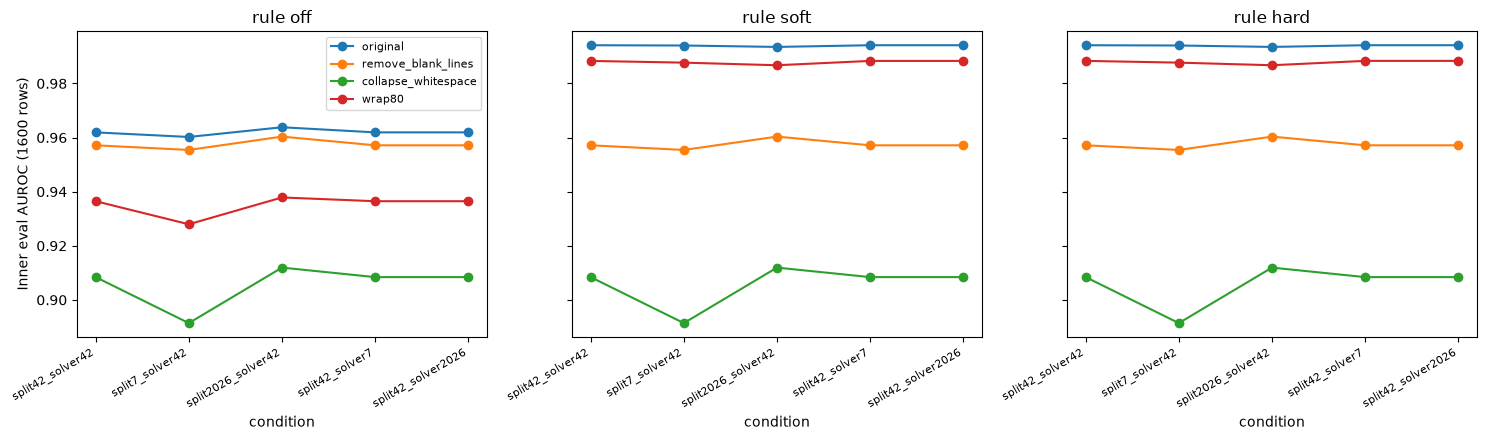

In [5]:
aurocs = pd.DataFrame(auroc_rows)
original = aurocs[aurocs.stress == "original"].set_index(["condition", "mode"]).auroc
aurocs["stress_loss"] = [original[(c, m)] - a for c, m, a in zip(aurocs.condition, aurocs["mode"], aurocs.auroc)]
display(aurocs.pivot_table(index=["condition", "stress"], columns="mode", values="auroc").round(6))
display(pd.DataFrame(fit_rows).drop(columns=[c for c in pd.DataFrame(fit_rows).columns if c.endswith("_reference")]))

def auroc_range(names):
    part = aurocs[(aurocs.stress == "original") & aurocs.condition.isin(names)]
    return {mode: {"min": float(g.auroc.min()), "max": float(g.auroc.max()), "range": float(g.auroc.max() - g.auroc.min())} for mode, g in part.groupby("mode")}
split_names = [f"split{s}_solver42" for s in SPLIT_SEEDS]
solver_names = ["split42_solver42"] + [f"split42_solver{s}" for s in SOLVER_SEEDS if s != 42]
sensitivity = {"split": auroc_range(split_names), "solver": auroc_range(solver_names)}
base_raw = raw_by_condition["split42_solver42"]["original"]
solver_margin = [{"condition": name, "arm": arm, "max_abs_raw_change_vs_solver42": float(np.max(np.abs(raw_by_condition[name]["original"][arm] - base_raw[arm])))}
                 for name in solver_names[1:] for arm in members]
stress_summary = (aurocs[aurocs.stress != "original"].groupby(["stress", "mode"]).stress_loss
                  .agg(["min", "mean", "max"]).reset_index())
margin_summary = pd.DataFrame(margin_rows).query("stress != 'original'").groupby(["stress", "arm"]).agg(
    max_abs_raw_change=("max_abs_raw_change", "max"), mean_abs_raw_change=("mean_abs_raw_change", "mean"),
    active_flags_min=("active_flags", "min"), active_flags_max=("active_flags", "max")).reset_index()
display(pd.DataFrame([{"source": k, "mode": m, **v} for k, d in sensitivity.items() for m, v in d.items()]))
display(pd.DataFrame(solver_margin)); display(stress_summary); display(margin_summary)
print(f"Five conditions, ten arm fits, scoring included: {run_seconds:.1f}s")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, mode in zip(axes, MODES):
    table = aurocs[aurocs["mode"] == mode].pivot(index="condition", columns="stress", values="auroc").loc[split_names + solver_names[1:], list(STRESSES)]
    for stress in table.columns:
        ax.plot(range(len(table)), table[stress], marker="o", label=stress)
    ax.set(xticks=range(len(table)), title=f"rule {mode}", xlabel="condition")
    ax.set_xticklabels(table.index, rotation=30, ha="right", fontsize=8)
axes[0].set_ylabel("Inner eval AUROC (1600 rows)"); axes[0].legend(fontsize=8)
fig.tight_layout(); plot_path = ROOT/"results"/NAME/f"{RUN_ID}-stress.png"; fig.savefig(plot_path, dpi=130); artifacts.append(plot_path); plt.show()

## Takeaway

- Tried: #11 soft ensemble on three inner 6400/1600 splits and three solver seeds, then four eval-only formatting stresses with rule off, soft, and hard.
- Found: solver seed does nothing measurable (AUROC range 0, max raw margin change 3e-6). Split range is .000625 soft and .003594 rule off. Formatting is the real risk: collapse whitespace loses .082 to .103 soft AUROC, removing blank lines loses .033 to .039, wrap80 loses about .006.
- Next: the rule is a blank-line shortcut. #14 should try formatting augmentation, and final picks should not trust soft gains on reformatted text.

## Save

Safe aggregates go to `results/12_seed_stress/`. Raw margins and the traceback, if any, stay under ignored `artifacts/12_seed_stress/`. No model is saved; this is a diagnostic, not a new candidate.

In [6]:
CONFIG["extra_versions"] = {name: importlib.metadata.version(name) for name in ["matplotlib", "threadpoolctl"]}
metrics = {"validation_auroc": None, "note": "inner original8000 diagnostic; frozen2000 not scored",
    "auroc_results": aurocs.to_dict("records"), "sensitivity_original": sensitivity, "solver_margin_changes": solver_margin,
    "stress_loss_summary": stress_summary.to_dict("records"), "stress_margin_summary": margin_summary.to_dict("records"),
    "margin_results": margin_rows, "fit_results": fit_rows, "run_seconds": run_seconds}
record_path = record_run(NAME, COMMAND, CONFIG, SEED, 6400, 1600, metrics, time.perf_counter() - START, artifacts=artifacts)
print("Saved", record_path.relative_to(ROOT))

Saved results/12_seed_stress/20261110T221222713672Z.json
